# Libraries

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Model Parameters (from slide specifications)

In [20]:
params = {
    'c_s': 420.0,     # Soil water holding capacity (mm)
    'alpha': 4.0,     # Runoff function shape parameter
    'gamma': 0.5,     # ET function shape parameter
    'beta_0': 0.8,    # Maximum of ET function
    'k_ext': 0.5      # Beer-Lambert light extinction coefficient
}

initial_sm = 0.9 * params['c_s']  # 378.0 mm


df = pd.read_csv("E:/VS_CODE_FILES/REMOTE_FILES/GitHub_Repos/Earth-System-Modelling/data/Data_swbm_Germany.csv")
df['time'] = pd.to_datetime(df['time'])

lam = 2.45      # Latent heat of vaporization (MJ/kg)
rho_w = 1000.0  # Water density (kg/m³)

# Driving Data (mm/day and m²/m²) 

P_mm = df['tp_[mm]'].clip(lower=0.0)
R_n_mm = ((df['snr_[MJ/m2]'] / (lam * rho_w)) * 1000.0).clip(lower=0.0)
LAI = df['lai_[m2/m2]'].clip(lower=0.0)

# Observations for Model Evaluation (mm and mm/day)

obs_sm_mm = df['sm_[m3/m3]'] * 1000.0
obs_ro_mm = df['ro_[m]'] * 1000.0
obs_et_mm = (df['le_[W/m2]'] * 86400.0) / (lam * 1e6)

# Model Components output

In [21]:
print("Model Components:")
print("\nParameters:")
for param, value in params.items():
  print(f"  {param}: {value}")
print(f"\nInitial Soil Moisture: {initial_sm:.1f} mm")
print("\nDriving Data Summary:")
print(f"  Total Rainfall (P): {driving_data['P'].sum():.1f} mm")
print(
    f"  Average Radiation (R_n): {driving_data['R_n'].mean():.2f} mm/day"
)

Model Components:

Parameters:
  c_s: 420.0
  alpha: 4.0
  gamma: 0.5
  beta_0: 0.8
  k_ext: 0.5

Initial Soil Moisture: 378.0 mm

Driving Data Summary:
  Total Rainfall (P): 13471.0 mm
  Average Radiation (R_n): 2.43 mm/day


# Core Flux & State Functions


In [22]:
def calculate_runoff(sm, precip, c_s, alpha):
    """Q_n = P_n * (w_n / c_s)^alpha"""
    rel_sm = np.clip(sm / c_s, 0.0, 1.0)
    return precip * (rel_sm ** alpha)

def calculate_canopy_fraction(lai, k_ext):
    """NEW FUNCTION: Beer-Lambert law for canopy radiation interception."""
    return 1.0 - np.exp(-k_ext * lai)

def calculate_et(sm, rad, c_s, beta_0, gamma, lai=None, k_ext=0.5):
    """ET_n = R_n_eq * beta_0 * (w_n / c_s)^gamma * f_canopy(LAI)"""
    rel_sm = np.clip(sm / c_s, 0.0, 1.0)
    canopy_factor = calculate_canopy_fraction(lai, k_ext) if lai is not None else 1.0
    return rad * beta_0 * (rel_sm ** gamma) * canopy_factor

def calculate_infiltration(precip, runoff):
    """Infiltration = P_n - Q_n"""
    return precip - runoff

# Simulation Loop

In [23]:
def run_swbm(P, R_n, params, lai_series=None):
    n = len(P)
    sm = np.zeros(n + 1)
    sm[0] = 0.9 * params['c_s']
    et_ts = np.zeros(n)
    q_ts = np.zeros(n)
    inf_ts = np.zeros(n)
    
    for t in range(n):
        lai_val = lai_series.iloc[t] if lai_series is not None else None
        q = calculate_runoff(sm[t], P.iloc[t], params['c_s'], params['alpha'])
        et = calculate_et(sm[t], R_n.iloc[t], params['c_s'], params['beta_0'], params['gamma'],
                          lai=lai_val, k_ext=params['k_ext'])
        inf = calculate_infiltration(P.iloc[t], q)
        
        sm[t + 1] = np.clip(sm[t] + P.iloc[t] - et - q, 0.0, params['c_s'])
        et_ts[t] = et
        q_ts[t] = q
        inf_ts[t] = inf
        
    return sm[:-1], et_ts, q_ts, inf_ts

# Run Baseline vs. Modified SWBM (+ LAI Canopy)

sm_base, et_base, q_base, _ = run_swbm(P_mm, R_n_mm, params, lai_series=None)
sm_mod, et_mod, q_mod, _ = run_swbm(P_mm, R_n_mm, params, lai_series=LAI)

# Evaluation

In [24]:
def print_metrics(label, sim_sm, sim_et, sim_q):
    sm_r = np.corrcoef(sim_sm, obs_sm_mm)[0, 1]
    sm_rmse = np.sqrt(np.mean((sim_sm - obs_sm_mm) ** 2))
    et_r = np.corrcoef(sim_et, obs_et_mm)[0, 1]
    et_rmse = np.sqrt(np.mean((sim_et - obs_et_mm) ** 2))
    q_r = np.corrcoef(sim_q, obs_ro_mm)[0, 1]
    print(f"{label:15s} | SM: r={sm_r:.3f}, RMSE={sm_rmse:.2f} mm | ET: r={et_r:.3f}, RMSE={et_rmse:.2f} mm/d | Q: r={q_r:.3f}")

print("Model Evaluation Summary (2008–2018):")
print("-" * 85)
print_metrics("Baseline SWBM", sm_base, et_base, q_base)
print_metrics("Modified + LAI", sm_mod, et_mod, q_mod)

Model Evaluation Summary (2008–2018):
-------------------------------------------------------------------------------------
Baseline SWBM   | SM: r=0.888, RMSE=33.83 mm | ET: r=0.884, RMSE=0.90 mm/d | Q: r=0.655
Modified + LAI  | SM: r=0.903, RMSE=23.20 mm | ET: r=0.909, RMSE=0.53 mm/d | Q: r=0.656


# Visualisation

<>:30: SyntaxWarning: invalid escape sequence '\c'
<>:30: SyntaxWarning: invalid escape sequence '\c'
C:\Users\SANGLAP ROY\AppData\Local\Temp\ipykernel_2600\595641306.py:30: SyntaxWarning: invalid escape sequence '\c'
  axes[1, 0].plot(lai_vals, f_canopy, '-', color='seagreen', lw=2.5, label='Modified: Beer–Lambert ($1 - e^{-0.5 \cdot LAI}$)')


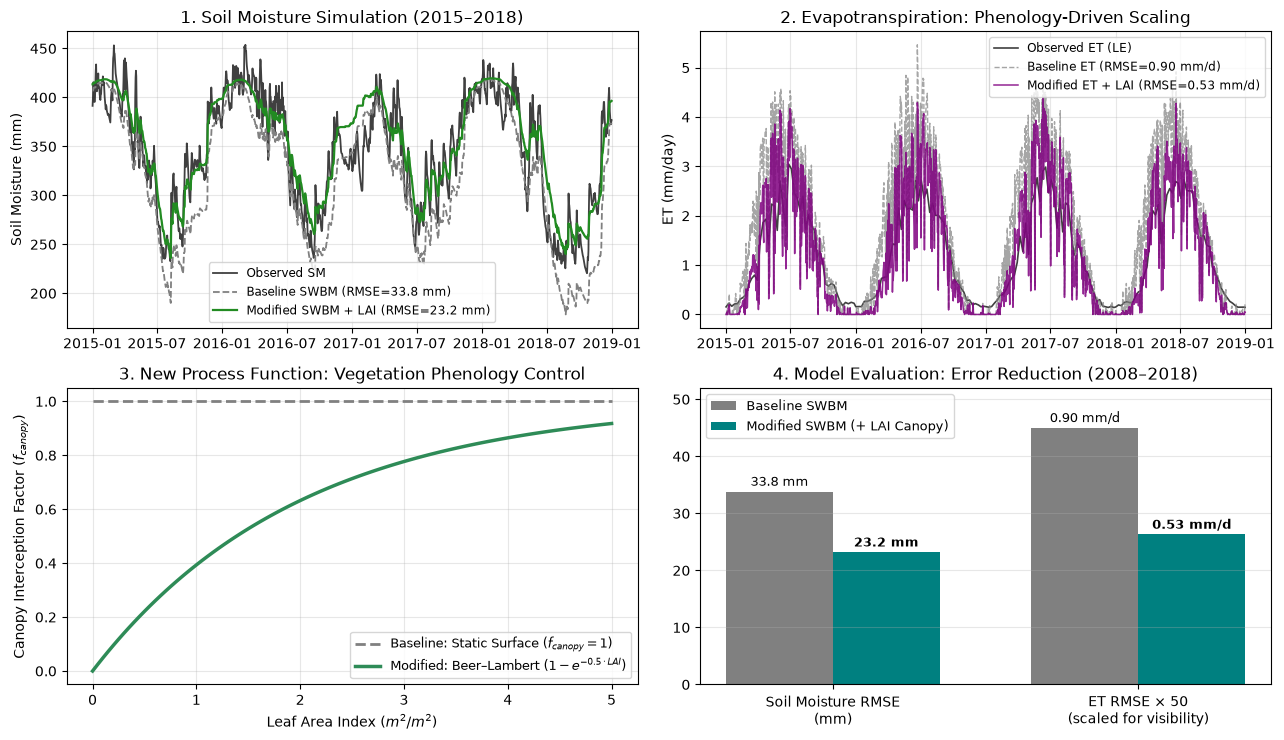

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
mask = df['time'] >= '2015-01-01'

# Panel 1: Soil Moisture Time Series
axes[0, 0].plot(df.loc[mask, 'time'], obs_sm_mm[mask], 'k-', alpha=0.75, lw=1.3, label='Observed SM')
axes[0, 0].plot(df.loc[mask, 'time'], sm_base[mask], '--', color='gray', lw=1.3,
                label=f'Baseline SWBM (RMSE={np.sqrt(np.mean((sm_base - obs_sm_mm)**2)):.1f} mm)')
axes[0, 0].plot(df.loc[mask, 'time'], sm_mod[mask], '-', color='forestgreen', lw=1.6,
                label=f'Modified SWBM + LAI (RMSE={np.sqrt(np.mean((sm_mod - obs_sm_mm)**2)):.1f} mm)')
axes[0, 0].set_ylabel('Soil Moisture (mm)')
axes[0, 0].set_title('1. Soil Moisture Simulation (2015–2018)')
axes[0, 0].legend(fontsize=8.5)
axes[0, 0].grid(alpha=0.3)

# Panel 2: Evapotranspiration Time Series
axes[0, 1].plot(df.loc[mask, 'time'], obs_et_mm[mask], 'k-', alpha=0.75, lw=1.2, label='Observed ET (LE)')
axes[0, 1].plot(df.loc[mask, 'time'], et_base[mask], '--', color='gray', alpha=0.7, lw=1.0,
                label=f'Baseline ET (RMSE={np.sqrt(np.mean((et_base - obs_et_mm)**2)):.2f} mm/d)')
axes[0, 1].plot(df.loc[mask, 'time'], et_mod[mask], '-', color='purple', alpha=0.85, lw=1.1,
                label=f'Modified ET + LAI (RMSE={np.sqrt(np.mean((et_mod - obs_et_mm)**2)):.2f} mm/d)')
axes[0, 1].set_ylabel('ET (mm/day)')
axes[0, 1].set_title('2. Evapotranspiration: Phenology-Driven Scaling')
axes[0, 1].legend(fontsize=8.5)
axes[0, 1].grid(alpha=0.3)

# Panel 3: Beer-Lambert Canopy Fraction Curve
lai_vals = np.linspace(0, 5, 100)
f_canopy = calculate_canopy_fraction(lai_vals, params['k_ext'])
axes[1, 0].plot(lai_vals, np.ones_like(lai_vals), '--', color='gray', lw=2, label='Baseline: Static Surface ($f_{canopy} = 1$)')
axes[1, 0].plot(lai_vals, f_canopy, '-', color='seagreen', lw=2.5, label='Modified: Beer–Lambert ($1 - e^{-0.5 \cdot LAI}$)')
axes[1, 0].set_xlabel('Leaf Area Index ($m^2/m^2$)')
axes[1, 0].set_ylabel('Canopy Interception Factor ($f_{canopy}$)')
axes[1, 0].set_title('3. New Process Function: Vegetation Phenology Control')
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(alpha=0.3)

# Panel 4: Error Reduction Bar Chart
metrics = ['Soil Moisture RMSE\n(mm)', 'ET RMSE × 50\n(scaled for visibility)']
base_vals = [np.sqrt(np.mean((sm_base - obs_sm_mm)**2)), np.sqrt(np.mean((et_base - obs_et_mm)**2)) * 50]
mod_vals = [np.sqrt(np.mean((sm_mod - obs_sm_mm)**2)), np.sqrt(np.mean((et_mod - obs_et_mm)**2)) * 50]
x = np.arange(len(metrics))
w = 0.35

axes[1, 1].bar(x - w/2, base_vals, w, label='Baseline SWBM', color='gray')
axes[1, 1].bar(x + w/2, mod_vals, w, label='Modified SWBM (+ LAI Canopy)', color='teal')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(metrics)
axes[1, 1].set_title('4. Model Evaluation: Error Reduction (2008–2018)')
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(axis='y', alpha=0.3)

axes[1, 1].text(0 - w/2, base_vals[0] + 1, f'{base_vals[0]:.1f} mm', ha='center', fontsize=9)
axes[1, 1].text(0 + w/2, mod_vals[0] + 1, f'{mod_vals[0]:.1f} mm', ha='center', fontsize=9, fontweight='bold')
axes[1, 1].text(1 - w/2, base_vals[1] + 1, f'{base_vals[1]/50:.2f} mm/d', ha='center', fontsize=9)
axes[1, 1].text(1 + w/2, mod_vals[1] + 1, f'{mod_vals[1]/50:.2f} mm/d', ha='center', fontsize=9, fontweight='bold')
axes[1, 1].set_ylim(0, 52)

plt.tight_layout()
plt.savefig('swbm_lai_presentation.png', dpi=200)
plt.show()